# YZM 411 Computer Vision Homework 1: Renk, Aydınlatma ve Örnekleme

**Öğrenci:** Osman ACAR — **No:** `230212016`

**Girdi dosyaları:** `Data/Gölge.jpg`, `Data/Normal.jpg`, `Data/Parlak.jpg` 
**Çıktılar:** `outputs/` klasörü (şekiller + CSV tabloları + `sonuc_tablosu.csv` vs. burada)

**Kural:** Her deneyin tahmin hücresi, o deneyin kodu çalıştırılmadan **önce** doldurulmuştur.

## 0. Ortam ve parametreler

In [21]:
import sys, platform
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python     :", sys.version.split()[0], "|", platform.platform())
print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("pandas     :", pd.__version__)
print("matplotlib :", matplotlib.__version__)
print("Çalışma klasörü:", Path.cwd())   # data/ klasörü bunun içinde olmalı

Python     : 3.13.1 | Windows-10-10.0.19045-SP0
NumPy      : 2.2.6
OpenCV     : 4.12.0
pandas     : 2.3.3
matplotlib : 3.10.7
Çalışma klasörü: c:\Users\User\Desktop\YZM 411 Ödev


In [22]:
# ---- Girdi / çıktı ----
DATA_DIR = Path("data")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
FILES = {                      # koşul adı -> dosya
    "normal": DATA_DIR / "Normal.jpg",
    "golge":  DATA_DIR / "Gölge.jpg",
    "lamba":  DATA_DIR / "Parlak.jpg",
}
CONDS = list(FILES)

# ---- Sabit deney parametreleri (ödevden) ----
B_SHIFT = 40                 # parlaklık kaydırması
GAMMAS = (0.5, 2.0)          # J = 255 * (I/255) ** gamma  (gamma formüldeki üs)
SCALE = 4                    # genişlik ve yükseklikte 1/4 küçültme

RESULTS = []                 # uzun formatlı sonuç tablosu: (bolum, kosul, olcu, deger)
def log(bolum, kosul, olcu, deger):
    RESULTS.append({"bolum": bolum, "kosul": kosul, "olcu": olcu, "deger": deger})

### Çekim kaydı (değişkenlerin kontrolü)
| Koşul | Dosya (orijinal ad) | Işık kaynağı | Kamera modu | Beyaz dengesi | ISO / enstantane | Not |
|---|---|---|---|---|---|---|
| normal | Normal.jpg (IMG_20261109_172419) | [Tavan ışığı / gün ışığı] | Otomatik | Otomatik | [ISO 1000] | Referans çekim; eşikler bu fotoğraftan belirlendi |
| gölge | Gölge.jpg (IMG_20261109_172449) | Normal ışık + [kitap/karton] ile düşürülen gölge | Otomatik | Otomatik | [ISO 6400] | Gölge defterin büyük kısmına ve kâğıdın bir bölümüne düşüyor |
| lamba | Parlak.jpg (IMG_20261109_172508) | Telefon flaşı (+ normal ortam ışığı) | Otomatik | Otomatik | [ISO 1250] | Ayrı bir lamba olmadığı için flaş kullanıldı; flaş kamerayla aynı açıdan ve eksenden geliyor. |

Telefon modeli: [XIAOMI] — Sabitleme: Telefon [kitap yığınına dayalı], çekimler arasında oynatılmadı — Zamanlayıcı: [Yok]
Çözünürlük: 4080 × 3060, JPEG. Hizalama kontrolü: normal→gölge ≈ 0,7 px, normal→lamba ≈ 1,2 px kayma (phase correlation).

*Otomatik pozlama ve beyaz dengesi açıktı. Bu nedenle fotoğraflar arasındaki farkın "yalnızca ışık değişiminden" kaynaklandığı iddia edilmez; kamera her çekimde pozlamayı ve renk dengesini kendisi ayarlamış olabilir. Flaş, ödevdeki "farklı lamba" koşulu yerine kullanılmıştır.*

## 1. Görüntüleri okuma ve ön kontroller

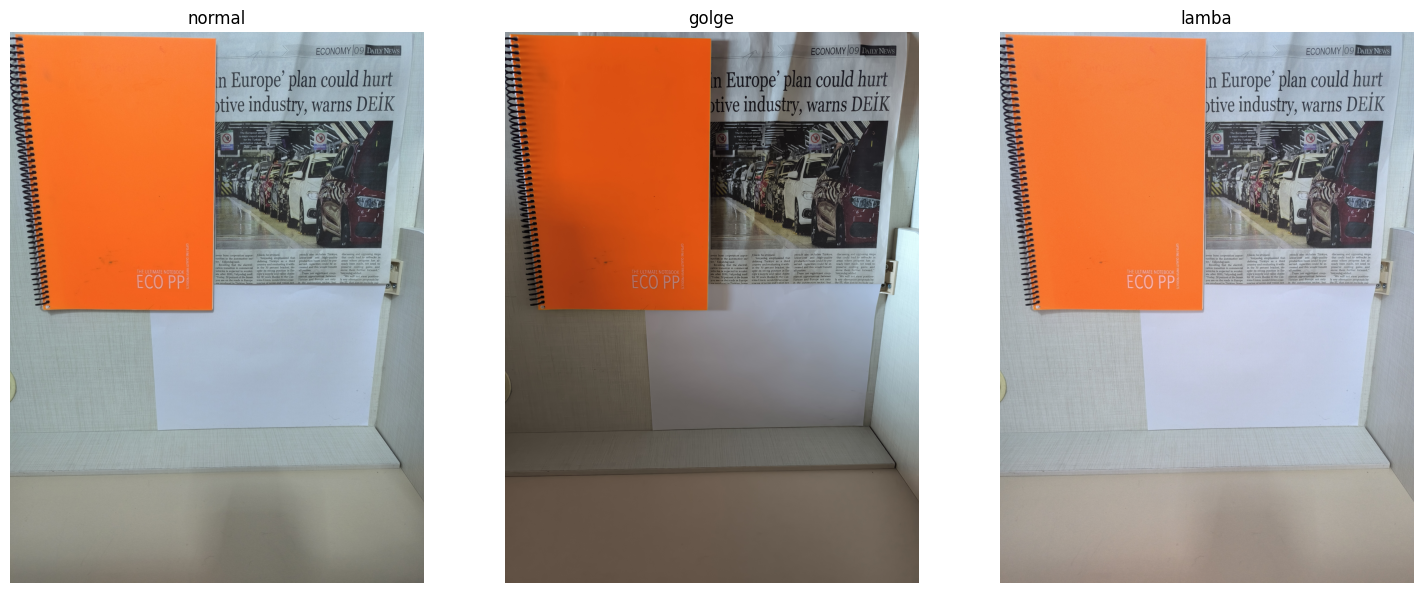

In [23]:
imgs_bgr, imgs_rgb = {}, {}
for k, p in FILES.items():
    # Windows'ta Türkçe karakterli yollarda (Masaüstü, Ödev...) cv2.imread None döndürür;
    # bu yüzden dosyayı NumPy ile okuyup cv2.imdecode ile çözüyoruz. Sonuç yine BGR, uint8.
    if not p.exists():
        raise FileNotFoundError(f"Bulunamadı: {p.resolve()}")
    im = cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(f"Okunamadı: {p}")
    imgs_bgr[k] = im
    imgs_rgb[k] = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, k in zip(ax, CONDS):
    a.imshow(imgs_rgb[k]); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "01_ozgun_fotograflar.png", dpi=120); plt.show()

In [24]:
# Kontrol 1: boyutlar aynı mı?   Kontrol 2: fotoğraflar hizalı mı?   Kontrol 3: 255'te kırpılma
shapes = {k: v.shape for k, v in imgs_bgr.items()}
print("Boyutlar:", shapes)
assert len(set(shapes.values())) == 1, "Fotoğrafların boyutu farklı!"

def gray_small(im, f=4):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32)
    g = cv2.resize(g, None, fx=1/f, fy=1/f, interpolation=cv2.INTER_AREA)
    g = (g - g.mean()) / (g.std() + 1e-6)      # ışık farkını azaltmak için normalize
    return g

ref = gray_small(imgs_bgr["normal"])
win = cv2.createHanningWindow(ref.shape[::-1], cv2.CV_32F)
for k in CONDS[1:]:
    (dx, dy), resp = cv2.phaseCorrelate(ref, gray_small(imgs_bgr[k]), win)
    print(f"normal -> {k}: kayma ≈ ({dx*4:+.1f}, {dy*4:+.1f}) px, güven={resp:.2f}")
    log("on_kontrol", k, "hizalama_kayma_px", float(np.hypot(dx, dy) * 4))

for k in CONDS:
    im = imgs_rgb[k]
    any255 = (im == 255).any(axis=2).mean() * 100
    all255 = (im == 255).all(axis=2).mean() * 100
    print(f"{k:7s} en az bir kanalı 255 olan piksel: %{any255:.2f} | üç kanalı da 255: %{all255:.2f}")
    log("on_kontrol", k, "kirpilma_herhangi_kanal_%", any255)

Boyutlar: {'normal': (4080, 3060, 3), 'golge': (4080, 3060, 3), 'lamba': (4080, 3060, 3)}
normal -> golge: kayma ≈ (+0.4, +0.6) px, güven=0.90
normal -> lamba: kayma ≈ (+0.8, +0.8) px, güven=0.99
normal  en az bir kanalı 255 olan piksel: %0.32 | üç kanalı da 255: %0.00
golge   en az bir kanalı 255 olan piksel: %0.09 | üç kanalı da 255: %0.00
lamba   en az bir kanalı 255 olan piksel: %0.10 | üç kanalı da 255: %0.00


**Tahmin :**
> Gölgede seçtiğim üç noktada (defter, beyaz kâğıt, masa) nesnelere daha az ışık ulaştığı için R, G ve B değerlerinin hepsinin azalmasını bekliyorum. Flaşlı çekimde ise değerlerin artarak 255'e yaklaşmasını bekliyorum. Hangi kanalın daha çok değişeceğini tahmin edemiyorum ama üçünün birlikte artacağını düşünüyorum.

In [25]:
im = imgs_bgr["normal"]
H, W, Cn = im.shape
print(f"H × W × C = {H} × {W} × {Cn}")
print("dtype     =", im.dtype)
print("aralık    =", im.min(), "-", im.max(), f"(teorik: {np.iinfo(im.dtype).min}-{np.iinfo(im.dtype).max})")
log("H1", "normal", "H", H); log("H1", "normal", "W", W); log("H1", "normal", "C", Cn)

H × W × C = 4080 × 3060 × 3
dtype     = uint8
aralık    = 0 - 255 (teorik: 0-255)


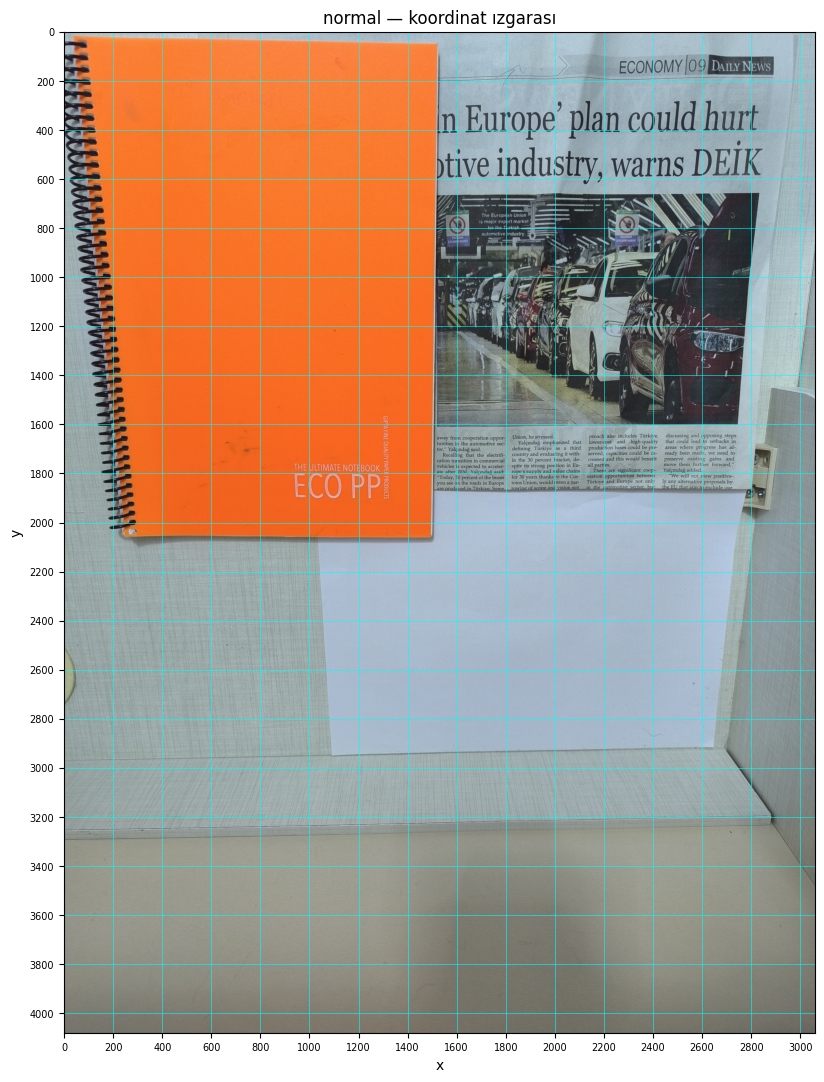

In [26]:
# Piksel seçimi için koordinat ızgarası (x yatay, y dikey)
def show_grid(img_rgb, step=200, title=""):
    fig, a = plt.subplots(figsize=(10, 13))
    a.imshow(img_rgb)
    a.set_xticks(np.arange(0, img_rgb.shape[1], step)); a.set_yticks(np.arange(0, img_rgb.shape[0], step))
    a.grid(color="cyan", lw=0.4); a.tick_params(labelsize=7)
    a.set_xlabel("x"); a.set_ylabel("y"); a.set_title(title)
    plt.show()

show_grid(imgs_rgb["normal"], title="normal — koordinat ızgarası")

In [27]:
# Koordinatlar fotoğraf boyutuna oranla verildi (çözünürlükten bağımsız)
H_img, W_img = imgs_bgr["normal"].shape[:2]
def px(fx, fy):
    return int(round(fx * W_img)), int(round(fy * H_img))
def box(fx0, fy0, fx1, fy1):
    return (*px(fx0, fy0), *px(fx1, fy1))

In [28]:
# >>> Aynı fiziksel bölgeden 3 piksel seçin: (ad, x, y)
POINTS = [("defter", *px(0.285, 0.233)),
          ("beyaz_kagit", *px(0.621, 0.621)),
          ("masa", *px(0.470, 0.930))]  # örn: [("defter", 600, 900), ("beyaz_kagit", 1200, 2000), ("masa", 900, 2400)]
assert POINTS is not None, "POINTS'i doldurun."

rows = []
for name, x, y in POINTS:
    row = {"nokta": name, "x": x, "y": y}
    for k in CONDS:
        r, g, b = imgs_rgb[k][y, x]               # NumPy erişimi: img[y, x, kanal]
        row[k] = f"({r}, {g}, {b})"
        for ch, v in zip("RGB", (r, g, b)):
            log("H1", k, f"{name}_{ch}", int(v))
    rows.append(row)
df_px = pd.DataFrame(rows)
df_px.to_csv(OUT_DIR / "H1_piksel_degerleri.csv", index=False, encoding="utf-8-sig")
display(df_px)

# BGR / RGB sırasının gösterimi (ilk nokta)
name, x, y = POINTS[0]
bgr, rgb = imgs_bgr["normal"], imgs_rgb["normal"]
print(f"\n'{name}' (x={x}, y={y})")
print("img_bgr[y, x]        ->", bgr[y, x], " (B, G, R sırası)")
print("img_bgr[y, x, ::-1]  ->", bgr[y, x, ::-1], " (elle ters çevrilmiş)")
print("img_rgb[y, x]        ->", rgb[y, x], " (cv2.cvtColor BGR2RGB)")
print("Tek kanal: img_rgb[y, x, 0] (R) =", rgb[y, x, 0])
assert (bgr[y, x, ::-1] == rgb[y, x]).all()
if x < H and y < W:
    print("Yanlış sıra img_rgb[x, y] ->", rgb[x, y], " (başka bir piksel!)")

,nokta,x,y,normal,golge,lamba
0,defter,872,951,"(252, 116, 40)","(223, 83, 21)","(246, 125, 56)"
1,beyaz_kagit,1900,2534,"(165, 181, 197)","(129, 127, 132)","(193, 200, 219)"
2,masa,1438,3794,"(137, 133, 122)","(104, 88, 75)","(162, 148, 137)"



'defter' (x=872, y=951)
img_bgr[y, x]        -> [ 40 116 252]  (B, G, R sırası)
img_bgr[y, x, ::-1]  -> [252 116  40]  (elle ters çevrilmiş)
img_rgb[y, x]        -> [252 116  40]  (cv2.cvtColor BGR2RGB)
Tek kanal: img_rgb[y, x, 0] (R) = 252
Yanlış sıra img_rgb[x, y] -> [255 122  45]  (başka bir piksel!)


In [29]:
# ---- Geliştirme 2: tek piksel yerine 5×5 bölge ortalaması ----
PATCH = 5
r = PATCH // 2
rows = []
for name, x, y in POINTS:
    for k in CONDS:
        p = imgs_rgb[k][y - r:y + r + 1, x - r:x + r + 1].reshape(-1, 3).astype(np.float64)
        mu, sd = p.mean(0), p.std(0)
        rows.append({"nokta": name, "kosul": k,
                     "tek_piksel": tuple(int(v) for v in imgs_rgb[k][y, x]),
                     "ort_R": round(mu[0], 1), "ort_G": round(mu[1], 1), "ort_B": round(mu[2], 1),
                     "std_R": round(sd[0], 1), "std_G": round(sd[1], 1), "std_B": round(sd[2], 1)})
        for ch, m in zip("RGB", mu):
            log("H1_patch", k, f"{name}_{ch}_ort", m)
df_patch = pd.DataFrame(rows)
df_patch.to_csv(OUT_DIR / "H1_patch_5x5.csv", index=False, encoding="utf-8-sig")
display(df_patch)

# Normal ışığa göre kanal oranları: 1'den küçük -> kararmış, büyük -> aydınlanmış
rows = []
for name, _, _ in POINTS:
    base = df_patch[(df_patch.nokta == name) & (df_patch.kosul == "normal")].iloc[0]
    for k in CONDS[1:]:
        cur = df_patch[(df_patch.nokta == name) & (df_patch.kosul == k)].iloc[0]
        row = {"nokta": name, "kosul": f"{k}/normal"}
        for ch in "RGB":
            row[ch] = round(cur[f"ort_{ch}"] / max(base[f"ort_{ch}"], 1e-6), 3)
        rows.append(row)
df_ratio = pd.DataFrame(rows)
df_ratio.to_csv(OUT_DIR / "H1_kanal_oranlari.csv", index=False, encoding="utf-8-sig")
display(df_ratio)
print("Oranlar üç kanalda eşitse ışık yalnızca şiddet değiştirmiş demektir; farklıysa renk de değişmiştir.")

,nokta,kosul,tek_piksel,ort_R,ort_G,ort_B,std_R,std_G,std_B
0,defter,normal,"(252, 116, 40)",249.8,113.8,38.5,1.5,1.5,1.7
1,defter,golge,"(223, 83, 21)",221.7,81.8,19.6,0.8,0.8,1.1
2,defter,lamba,"(246, 125, 56)",245.5,124.6,55.6,1.9,2.0,1.9
3,beyaz_kagit,normal,"(165, 181, 197)",163.9,179.9,195.9,1.8,1.8,1.8
4,beyaz_kagit,golge,"(129, 127, 132)",127.9,125.9,130.9,0.7,0.7,0.7
5,beyaz_kagit,lamba,"(193, 200, 219)",193.0,200.0,219.0,2.2,2.2,2.2
6,masa,normal,"(137, 133, 122)",134.2,130.2,119.2,1.8,1.8,1.8
7,masa,golge,"(104, 88, 75)",103.4,87.4,74.4,0.9,0.9,0.9
8,masa,lamba,"(162, 148, 137)",164.2,149.8,138.9,2.3,2.3,2.2


,nokta,kosul,R,G,B
0,defter,golge/normal,0.888,0.719,0.509
1,defter,lamba/normal,0.983,1.095,1.444
2,beyaz_kagit,golge/normal,0.780,0.700,0.668
3,beyaz_kagit,lamba/normal,1.178,1.112,1.118
4,masa,golge/normal,0.770,0.671,0.624
5,masa,lamba/normal,1.224,1.151,1.165


Oranlar üç kanalda eşitse ışık yalnızca şiddet değiştirmiş demektir; farklıysa renk de değişmiştir.


**Tahmin:**
> Gölgede RGB maskesinin daha çok küçülmesini bekliyorum, çünkü gölge R, G ve B değerlerinin hepsini düşüreceği için defterin pikselleri normal ışıkta belirlenen eşiklerin altında kalacak. Flaşlı çekimde ise maskelerin küçülmesini beklemiyorum. Aynı kalmasını veya artmasını bekliyorum. 

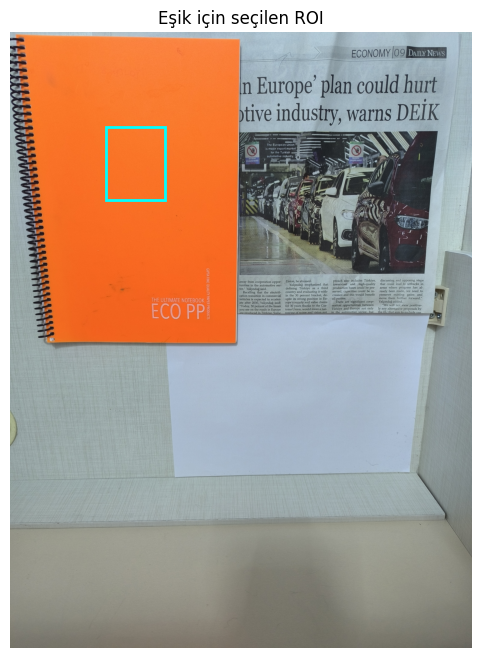

,RGB:R,RGB:G,RGB:B,HSV:H,HSV:S,HSV:V
p1,246.0,110.0,35.0,10.0,208.0,246.0
p5,247.0,111.0,36.0,11.0,210.0,247.0
p50,250.0,116.0,40.0,11.0,214.0,250.0
p95,253.0,122.0,45.0,11.0,218.0,253.0
p99,255.0,124.0,47.0,11.0,219.0,255.0


Not: OpenCV 8-bit HSV -> H 0-179, S ve V 0-255. Turuncu/kırmızı tonlar H=0 civarında; 0/179 sarmalanmasına dikkat.


In [30]:
# >>> Normal ışıklı fotoğrafta nesnenin küçük bir bölgesi: (x0, y0, x1, y1)
ROI = box(0.207, 0.155, 0.336, 0.272)        # defterin sol üst kısmı, lekeden uzak      # örn: (300, 600, 700, 1000)
assert ROI is not None, "ROI'yi doldurun."
x0, y0, x1, y1 = ROI

rgb_n = imgs_rgb["normal"]; hsv_n = cv2.cvtColor(imgs_bgr["normal"], cv2.COLOR_BGR2HSV)
fig, a = plt.subplots(figsize=(6, 8)); a.imshow(rgb_n)
a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2)); a.set_title("Eşik için seçilen ROI"); a.axis("off")
plt.savefig(OUT_DIR / "02_roi.png", dpi=120); plt.show()

q = [1, 5, 50, 95, 99]
stats = {}
for nm, im3, chs in (("RGB", rgb_n, "RGB"), ("HSV", hsv_n, "HSV")):
    patch = im3[y0:y1, x0:x1].reshape(-1, 3)
    for i, ch in enumerate(chs):
        stats[f"{nm}:{ch}"] = np.percentile(patch[:, i], q)
display(pd.DataFrame(stats, index=[f"p{v}" for v in q]).round(1))
print("Not: OpenCV 8-bit HSV -> H 0-179, S ve V 0-255. Turuncu/kırmızı tonlar H=0 civarında; 0/179 sarmalanmasına dikkat.")

In [31]:
# >>> Eşikleri yalnızca yukarıdaki normal-ışık istatistiğine bakarak BİR KEZ belirleyin ve dondurun.
# cv2.inRange alt ve üst sınırları KAPSAR.  Format: (alt, üst)  -> RGB sırasında / HSV sırasında
THRESH_RGB = ((226, 90, 15), (255, 144, 67))
THRESH_HSV = ((7, 188, 226), (14, 239, 255))   # örn: ((180,  60,   0), (255, 170, 90))
   # örn: ((  3, 150, 120), ( 20, 255, 255))   H_alt > H_üst ise 0/179 sarmalanır
assert THRESH_RGB is not None and THRESH_HSV is not None, "Eşikleri doldurun."
print("Dondurulan eşikler -> RGB:", THRESH_RGB, "| HSV:", THRESH_HSV)

def mask_rgb(img_rgb, th):
    return cv2.inRange(img_rgb, np.array(th[0], np.uint8), np.array(th[1], np.uint8))

def mask_hsv(img_bgr, th):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    (hl, sl, vl), (hh, sh, vh) = th
    if hl <= hh:
        return cv2.inRange(hsv, np.array((hl, sl, vl), np.uint8), np.array((hh, sh, vh), np.uint8))
    m1 = cv2.inRange(hsv, np.array((hl, sl, vl), np.uint8), np.array((179, sh, vh), np.uint8))
    m2 = cv2.inRange(hsv, np.array((0, sl, vl), np.uint8), np.array((hh, sh, vh), np.uint8))
    return cv2.bitwise_or(m1, m2)

masks = {}
for k in CONDS:
    masks[("RGB", k)] = mask_rgb(imgs_rgb[k], THRESH_RGB)
    masks[("HSV", k)] = mask_hsv(imgs_bgr[k], THRESH_HSV)

Dondurulan eşikler -> RGB: ((226, 90, 15), (255, 144, 67)) | HSV: ((7, 188, 226), (14, 239, 255))


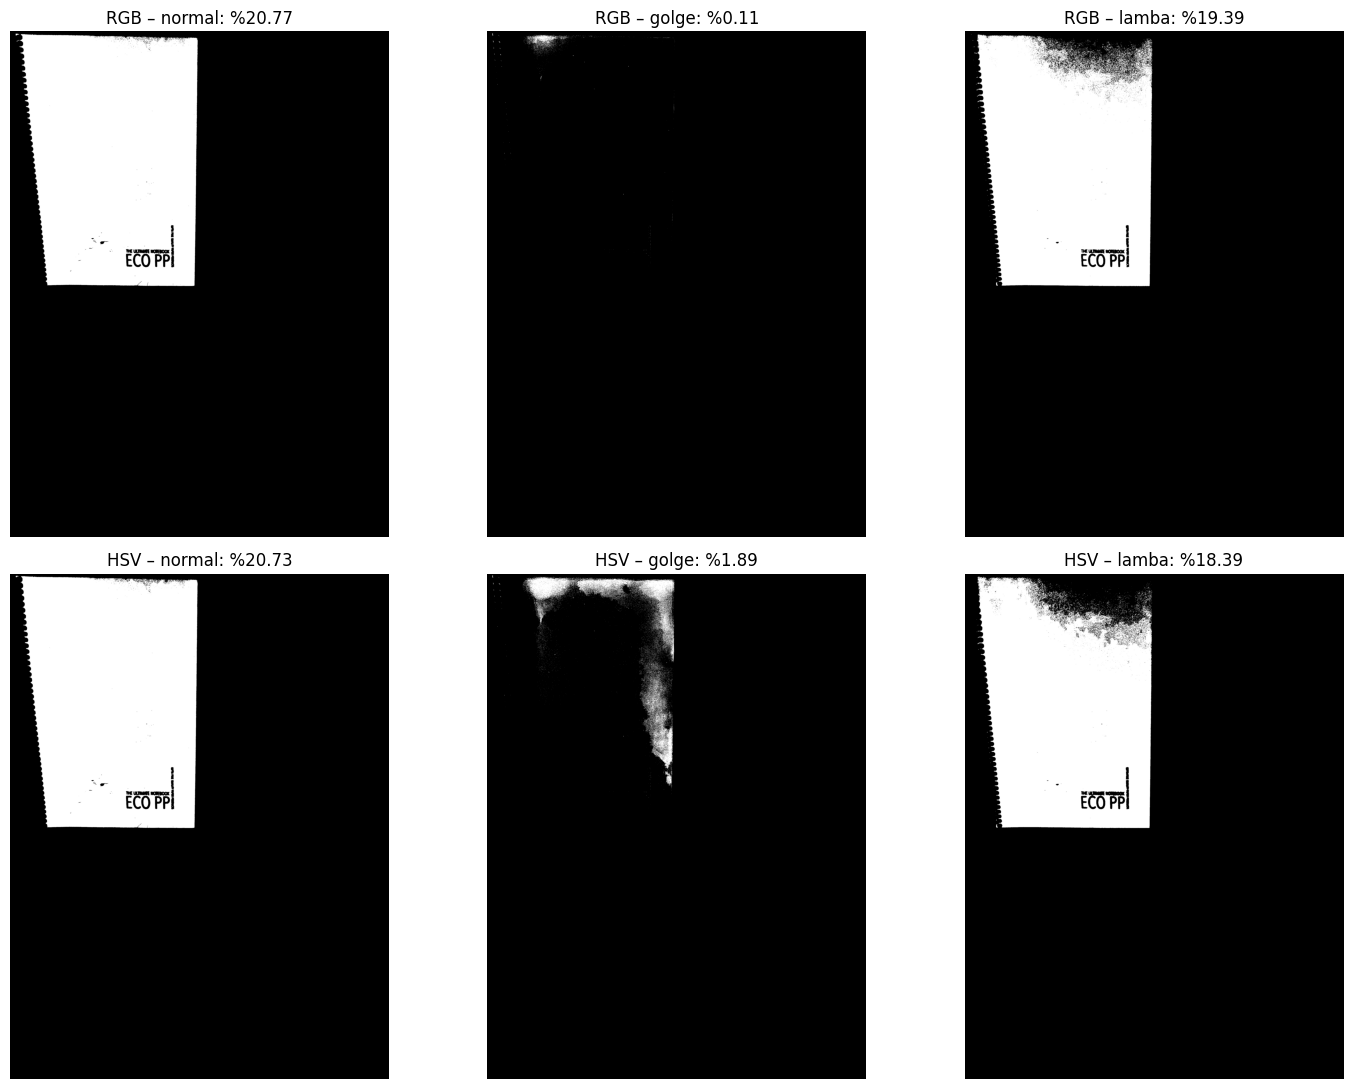

,uzay,kosul,secilen_piksel,alan_orani_%,kutu_disi_pay_%
0,RGB,normal,2593148,20.770,0.96
1,RGB,golge,13792,0.110,2.42
2,RGB,lamba,2421407,19.395,0.92
3,HSV,normal,2588458,20.733,0.91
4,HSV,golge,236354,1.893,0.11
5,HSV,lamba,2295456,18.386,0.86


In [32]:
# Opsiyonel: nesnenin (defter) kaba sınır kutusu -> seçilen piksellerin ne kadarının kutu DIŞINDA kaldığı.
# Bu bir doğruluk ölçütü DEĞİLDİR; yalnızca maskenin nereye dağıldığını gösterir.
OBJ_BOX = box(0.052, 0.0, 0.497, 0.505)      # defterin kaba sınır kutusu  # örn: (100, 0, 1000, 1350)

rows = []
fig, ax = plt.subplots(2, 3, figsize=(15, 11))
for i, sp in enumerate(("RGB", "HSV")):
    for j, k in enumerate(CONDS):
        m = masks[(sp, k)] > 0
        ratio = m.mean() * 100
        row = {"uzay": sp, "kosul": k, "secilen_piksel": int(m.sum()), "alan_orani_%": round(ratio, 3)}
        log("H2", k, f"{sp}_alan_orani_%", ratio)
        if OBJ_BOX is not None and m.sum() > 0:
            bx0, by0, bx1, by1 = OBJ_BOX
            inside = m[by0:by1, bx0:bx1].sum()
            row["kutu_disi_pay_%"] = round((1 - inside / m.sum()) * 100, 2)
            log("H2", k, f"{sp}_kutu_disi_pay_%", row["kutu_disi_pay_%"])
        rows.append(row)
        ax[i, j].imshow(m, cmap="gray"); ax[i, j].axis("off")
        ax[i, j].set_title(f"{sp} – {k}: %{ratio:.2f}")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_alti_maske.png", dpi=120); plt.show()

df_mask = pd.DataFrame(rows)
df_mask.to_csv(OUT_DIR / "H2_maske_oranlari.csv", index=False, encoding="utf-8-sig")
display(df_mask)

In [33]:
# Aynı ROI'nin üç fotoğraftaki ortalama değerleri: ışık nesneyi gerçekte ne kadar değiştirdi?
rows = []
for k in CONDS:
    pr = imgs_rgb[k][y0:y1, x0:x1].reshape(-1, 3).astype(float)
    ph = cv2.cvtColor(imgs_bgr[k], cv2.COLOR_BGR2HSV)[y0:y1, x0:x1].reshape(-1, 3).astype(float)
    r = {"kosul": k}
    for ch, v in zip("RGB", pr.mean(0)): r[f"ort_{ch}"] = round(v, 1)
    for ch, v in zip("HSV", ph.mean(0)): r[f"ort_{ch}"] = round(v, 1)
    for col in ("ort_R", "ort_G", "ort_B", "ort_H", "ort_S", "ort_V"):
        log("H2_roi", k, col, r[col])
    rows.append(r)
df_roi = pd.DataFrame(rows); df_roi.to_csv(OUT_DIR / "H2_roi_ortalamalari.csv", index=False, encoding="utf-8-sig")
display(df_roi)

,kosul,ort_R,ort_G,ort_B,ort_H,ort_S,ort_V
0,normal,250.1,116.4,40.0,11.0,214.2,250.1
1,golge,221.3,81.5,19.1,9.1,232.9,221.3
2,lamba,246.5,124.8,57.1,10.9,195.9,246.5


normal  kâğıt ort. RGB = [167.7 183.7 202.2] | std = [3.  3.2 3.2]
golge   kâğıt ort. RGB = [126.5 124.8 128.6] | std = [ 9.1 11.5 14.5]
lamba   kâğıt ort. RGB = [195.8 202.6 223.8] | std = [3.7 3.2 3.7]
Not: std büyükse kâğıt üzerinde ışık düzgün değildir (ör. gölge kâğıdın bir kısmında).


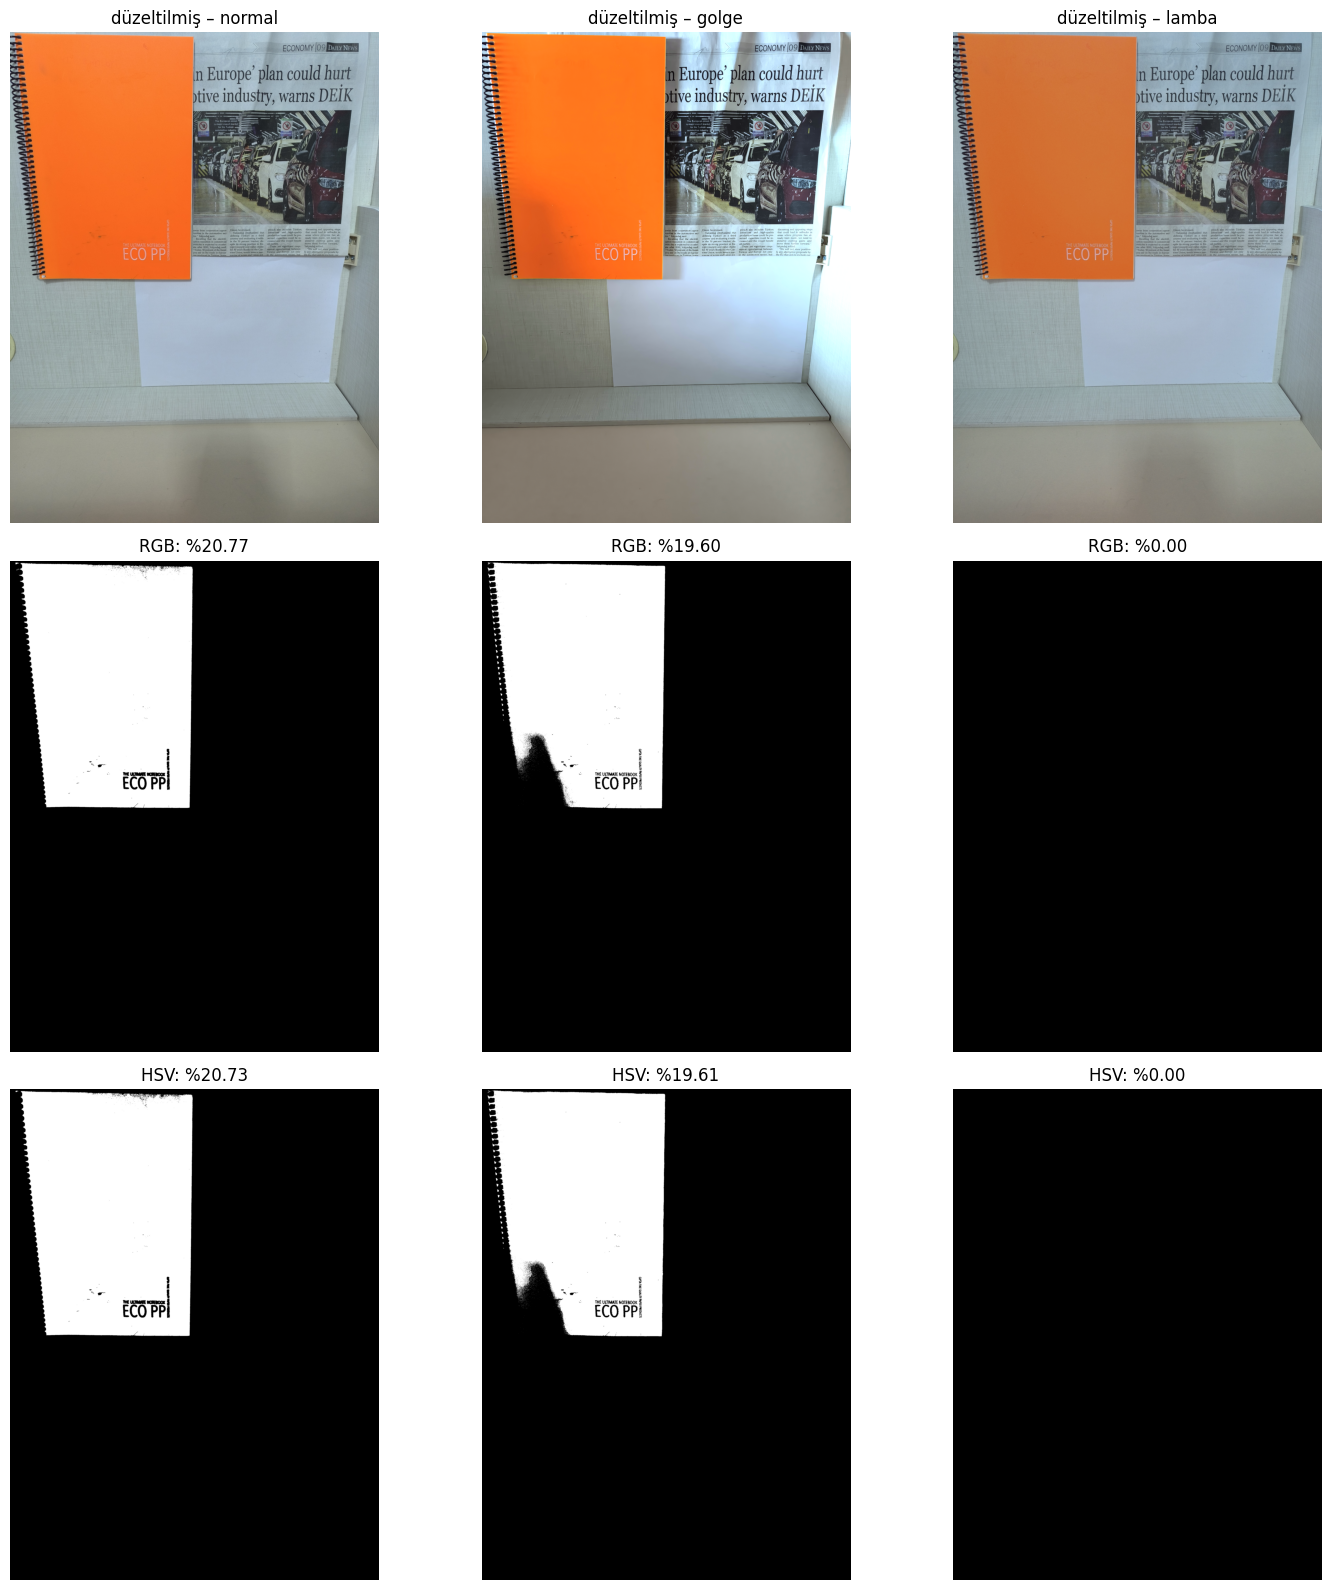

,uzay,kosul,once_%,duzeltme_sonrasi_%
0,RGB,normal,20.770,20.770
1,HSV,normal,20.733,20.733
2,RGB,golge,0.110,19.603
3,HSV,golge,1.893,19.612
4,RGB,lamba,19.395,0.000
5,HSV,lamba,18.386,0.000


In [34]:
# ---- Geliştirme 3: beyaz kâğıtla basit ışık düzeltmesi (kanal başına ölçekleme) ----
# Her fotoğrafı, beyaz kâğıdın renginin normal fotoğraftaki kâğıt rengine eşit olacağı şekilde ölçekliyoruz.
# Eşikler DEĞİŞMİYOR; aynı dondurulmuş eşikler düzeltilmiş görüntülere uygulanıyor.
PAPER_BOX = box(0.45, 0.56, 0.75, 0.68)      # beyaz A4'ün ortası
px0, py0, px1, py1 = PAPER_BOX

paper = {}
for k in CONDS:
    p = imgs_rgb[k][py0:py1, px0:px1].reshape(-1, 3).astype(np.float64)
    paper[k] = p.mean(0)
    print(f"{k:7s} kâğıt ort. RGB = {np.round(p.mean(0), 1)} | std = {np.round(p.std(0), 1)}")
print("Not: std büyükse kâğıt üzerinde ışık düzgün değildir (ör. gölge kâğıdın bir kısmında).")

def white_normalize(img_rgb, ref_now, ref_target):
    gain = ref_target / np.maximum(ref_now, 1e-6)
    return np.clip(img_rgb.astype(np.float64) * gain, 0, 255).round().astype(np.uint8)

norm_rgb = {k: white_normalize(imgs_rgb[k], paper[k], paper["normal"]) for k in CONDS}

rows = []
fig, ax = plt.subplots(3, 3, figsize=(15, 16))
for j, k in enumerate(CONDS):
    nb = cv2.cvtColor(norm_rgb[k], cv2.COLOR_RGB2BGR)
    m_rgb = mask_rgb(norm_rgb[k], THRESH_RGB) > 0
    m_hsv = mask_hsv(nb, THRESH_HSV) > 0
    ax[0, j].imshow(norm_rgb[k]); ax[0, j].set_title(f"düzeltilmiş – {k}")
    ax[1, j].imshow(m_rgb, cmap="gray"); ax[1, j].set_title(f"RGB: %{m_rgb.mean()*100:.2f}")
    ax[2, j].imshow(m_hsv, cmap="gray"); ax[2, j].set_title(f"HSV: %{m_hsv.mean()*100:.2f}")
    for a in ax[:, j]: a.axis("off")
    for sp, m in (("RGB", m_rgb), ("HSV", m_hsv)):
        before = (masks[(sp, k)] > 0).mean() * 100
        rows.append({"uzay": sp, "kosul": k, "once_%": round(before, 3), "duzeltme_sonrasi_%": round(m.mean() * 100, 3)})
        log("H2_beyaz_duzeltme", k, f"{sp}_alan_orani_%", m.mean() * 100)
plt.tight_layout(); plt.savefig(OUT_DIR / "06_beyaz_kagit_duzeltmesi.png", dpi=110); plt.show()

df_wb = pd.DataFrame(rows)
df_wb.to_csv(OUT_DIR / "H2_beyaz_duzeltme.csv", index=False, encoding="utf-8-sig")
display(df_wb)

**Tahmin :** 
> b = +40: Ortalamanın yaklaşık 185,4 olmasını bekliyorum. Ancak 255'e yakın pikseller kırpılacağı için ölçülen değerin bundan biraz daha az çıkacağını düşünüyorum.
> γ = 0,5: Görüntünün aydınlanmasını ve ortalamanın yaklaşık 192,6 olmasını bekliyorum.
> γ = 2,0: Görüntünün kararmasını ve ortalamanın yaklaşık 82,9 olmasını bekliyorum.

In [35]:
def brightness_shift(I, b):
    # J = clip(I + b, 0, 255) — float üzerinde
    return np.clip(I.astype(np.float64) + b, 0, 255)

def gamma_transform(I, gamma):
    # J = 255 * (I/255) ** gamma — float üzerinde
    return np.clip(255.0 * (I.astype(np.float64) / 255.0) ** gamma, 0, 255)

# Ödevdeki örnekle doğrulama: 64 -> ~128 (γ=0.5), ~16 (γ=2.0)
print("64 için γ=0.5 ->", gamma_transform(np.array([64]), 0.5)[0].round(2),
      "| γ=2.0 ->", gamma_transform(np.array([64]), 2.0)[0].round(2))

64 için γ=0.5 -> 127.75 | γ=2.0 -> 16.06


,donusum,ortalama_once,formul_ortalamaya,olculen_ortalama,fark,kirpilan_deger_%
0,özgün,145.42,145.42,145.42,0.00,NaN
1,b=+40,145.42,185.42,183.08,-2.34,7.32
2,γ=0.5,145.42,192.57,188.36,-4.21,0.00
3,γ=2.0,145.42,82.93,94.33,11.40,0.00


b=+40: 255'te kırpılan piksel (en az bir kanal): %21.95
Kırpma yüzünden kaybolan toplam artış: ortalamada 2.34 seviye


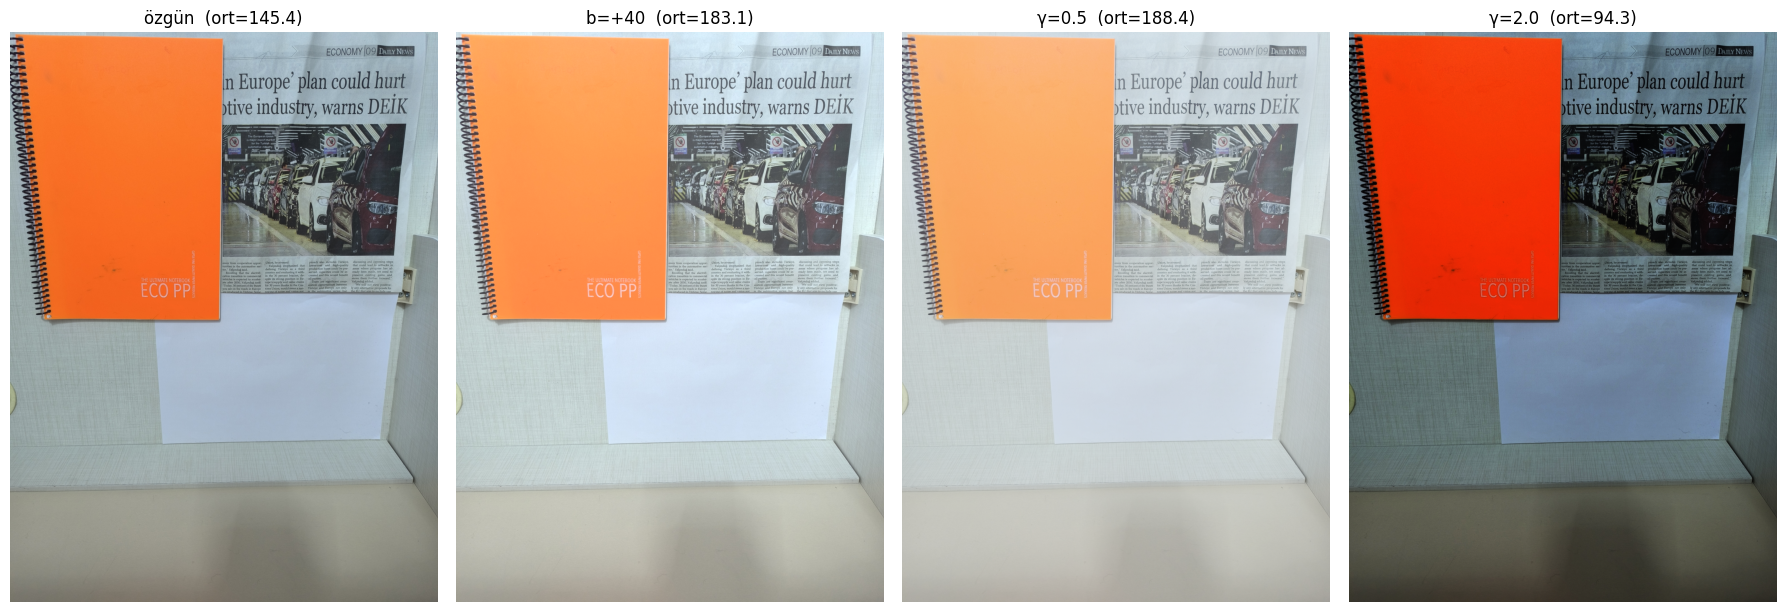

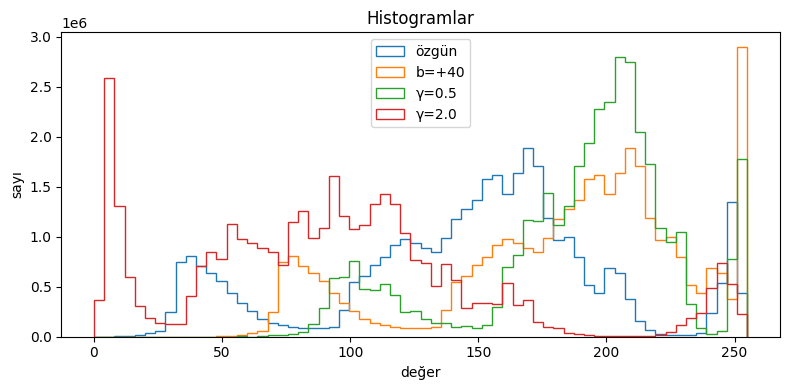

In [36]:
I = imgs_rgb["normal"]
I_f = I.astype(np.float64)
m0 = I_f.mean()
outs = {"özgün": I_f, f"b=+{B_SHIFT}": brightness_shift(I, B_SHIFT)}
for g in GAMMAS:
    outs[f"γ={g}"] = gamma_transform(I, g)

rows = []
for name, J in outs.items():
    if name == "özgün":
        naive = m0; clipped = np.nan
    elif name.startswith("b="):
        naive = m0 + B_SHIFT
        clipped = ((I_f + B_SHIFT) > 255).mean() * 100   # kırpılan kanal değeri oranı
    else:
        g = float(name.split("=")[1])
        naive = 255 * (m0 / 255) ** g                      # formülü ortalamaya uygulamak
        clipped = 0.0
    rows.append({"donusum": name, "ortalama_once": round(m0, 2),
                 "formul_ortalamaya": round(naive, 2), "olculen_ortalama": round(J.mean(), 2),
                 "fark": round(J.mean() - naive, 2), "kirpilan_deger_%": None if np.isnan(clipped) else round(clipped, 2)})
    log("H3", "normal", f"{name}_olculen_ortalama", J.mean())
df_tone = pd.DataFrame(rows); df_tone.to_csv(OUT_DIR / "H3_parlaklik_gama.csv", index=False, encoding="utf-8-sig")
display(df_tone)

if B_SHIFT > 0:
    sat = (I_f + B_SHIFT > 255)
    print(f"b=+{B_SHIFT}: 255'te kırpılan piksel (en az bir kanal): %{sat.any(axis=2).mean()*100:.2f}")
    print(f"Kırpma yüzünden kaybolan toplam artış: ortalamada {(m0 + B_SHIFT) - outs[f'b=+{B_SHIFT}'].mean():.2f} seviye")

fig, ax = plt.subplots(1, 4, figsize=(18, 6))
for a, (name, J) in zip(ax, outs.items()):
    a.imshow(J.round().astype(np.uint8)); a.set_title(f"{name}  (ort={J.mean():.1f})"); a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "04_parlaklik_gama.png", dpi=120); plt.show()

fig, a = plt.subplots(figsize=(8, 4))
for name, J in outs.items():
    a.hist(J.ravel(), bins=64, range=(0, 255), histtype="step", label=name)
a.set_xlabel("değer"); a.set_ylabel("sayı"); a.legend(); a.set_title("Histogramlar")
plt.tight_layout(); plt.savefig(OUT_DIR / "04b_histogramlar.png", dpi=120); plt.show()

**Tahmin:**
> Genişlik ve yükseklikte 1/4 küçültmede harflerin boyu dörtte birine ineceği için gazetedeki küçük yazının okunamaz hâle gelmesini bekliyorum. En yakın komşu yönteminin harfleri bulanı ve gri, alan ortalaması yönteminin ise kopuk ve kırık göstermesini ayrıca büyütmenin ise kaybolan ayrıntıyı geri getirmemesini bekliyorum.

Kesit: (228, 1200, 3) -> küçük: (57, 300, 3)


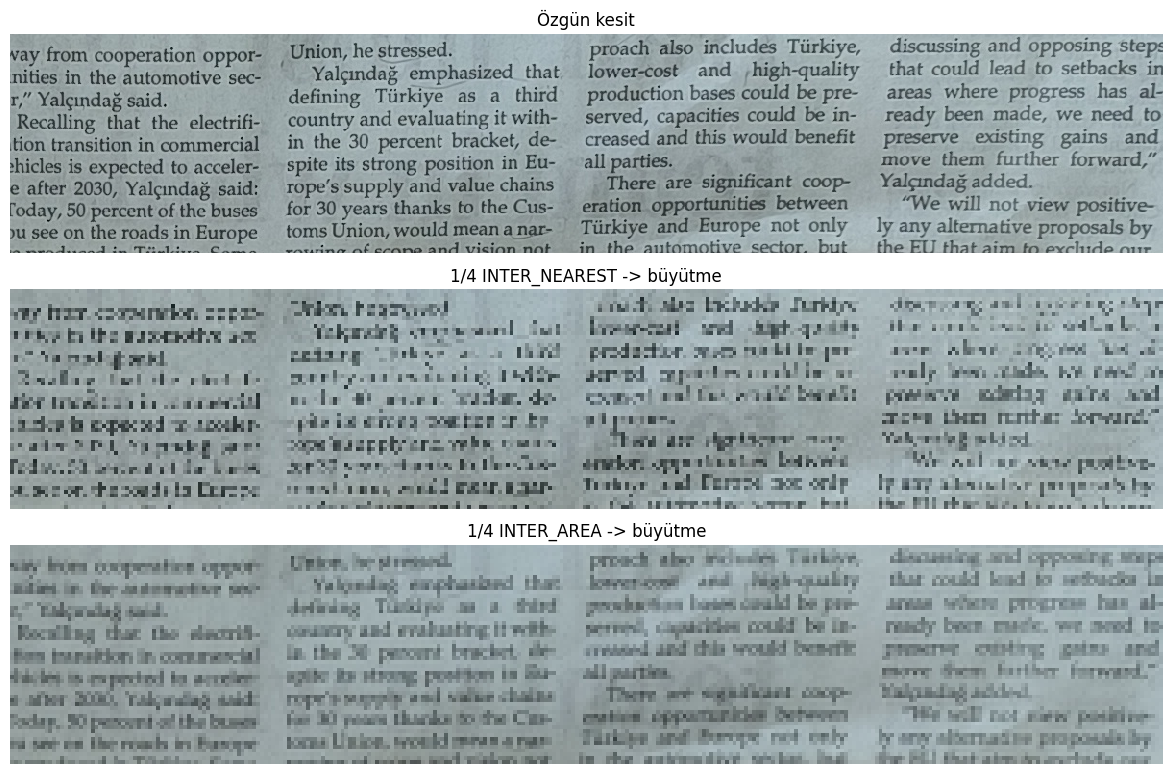

,yontem,MAE,PSNR_dB
0,INTER_NEAREST,20.82,16.87
1,INTER_AREA,15.87,20.19


Not: PSNR yalnızca piksel farkını ölçer; okunabilirliği değil.


In [37]:
# >>> Yazılı / çizgili bölge: (x0, y0, x1, y1) — normal fotoğraftan
TEXT_BOX = box(0.502, 0.400, 0.895, 0.456)   # gazetenin küçük puntolu sütunları  # örn: (1000, 1100, 1800, 1300)
assert TEXT_BOX is not None, "TEXT_BOX'ı doldurun."
tx0, ty0, tx1, ty1 = TEXT_BOX
crop = imgs_rgb["normal"][ty0:ty1, tx0:tx1]
h, w = (crop.shape[0] // SCALE) * SCALE, (crop.shape[1] // SCALE) * SCALE
crop = crop[:h, :w]                                  # 4'e tam bölünsün
small_size = (w // SCALE, h // SCALE)                # cv2.resize -> (genişlik, yükseklik)

down = {
    "INTER_NEAREST": cv2.resize(crop, small_size, interpolation=cv2.INTER_NEAREST),
    "INTER_AREA":    cv2.resize(crop, small_size, interpolation=cv2.INTER_AREA),
}
# Yalnızca göstermek için en yakın komşuyla özgün boyuta büyütme
up = {k: cv2.resize(v, (w, h), interpolation=cv2.INTER_NEAREST) for k, v in down.items()}
print("Kesit:", crop.shape, "-> küçük:", down["INTER_AREA"].shape)

fig, ax = plt.subplots(3, 1, figsize=(12, min(20, 3 * 12 * h / w + 1)))
for a, (t, im) in zip(ax, [("Özgün kesit", crop), ("1/4 INTER_NEAREST -> büyütme", up["INTER_NEAREST"]),
                           ("1/4 INTER_AREA -> büyütme", up["INTER_AREA"])]):
    a.imshow(im, interpolation="nearest"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "05_kucultme_karsilastirma.png", dpi=150); plt.show()

rows = []
for k, u in up.items():
    diff = u.astype(float) - crop.astype(float)
    mse = (diff ** 2).mean()
    psnr = 10 * np.log10(255 ** 2 / mse) if mse > 0 else np.inf
    rows.append({"yontem": k, "MAE": round(np.abs(diff).mean(), 2), "PSNR_dB": round(psnr, 2)})
    log("H4", "normal", f"{k}_PSNR_dB", psnr)
df_ds = pd.DataFrame(rows); df_ds.to_csv(OUT_DIR / "H4_kucultme.csv", index=False, encoding="utf-8-sig")
display(df_ds)
print("Not: PSNR yalnızca piksel farkını ölçer; okunabilirliği değil.")

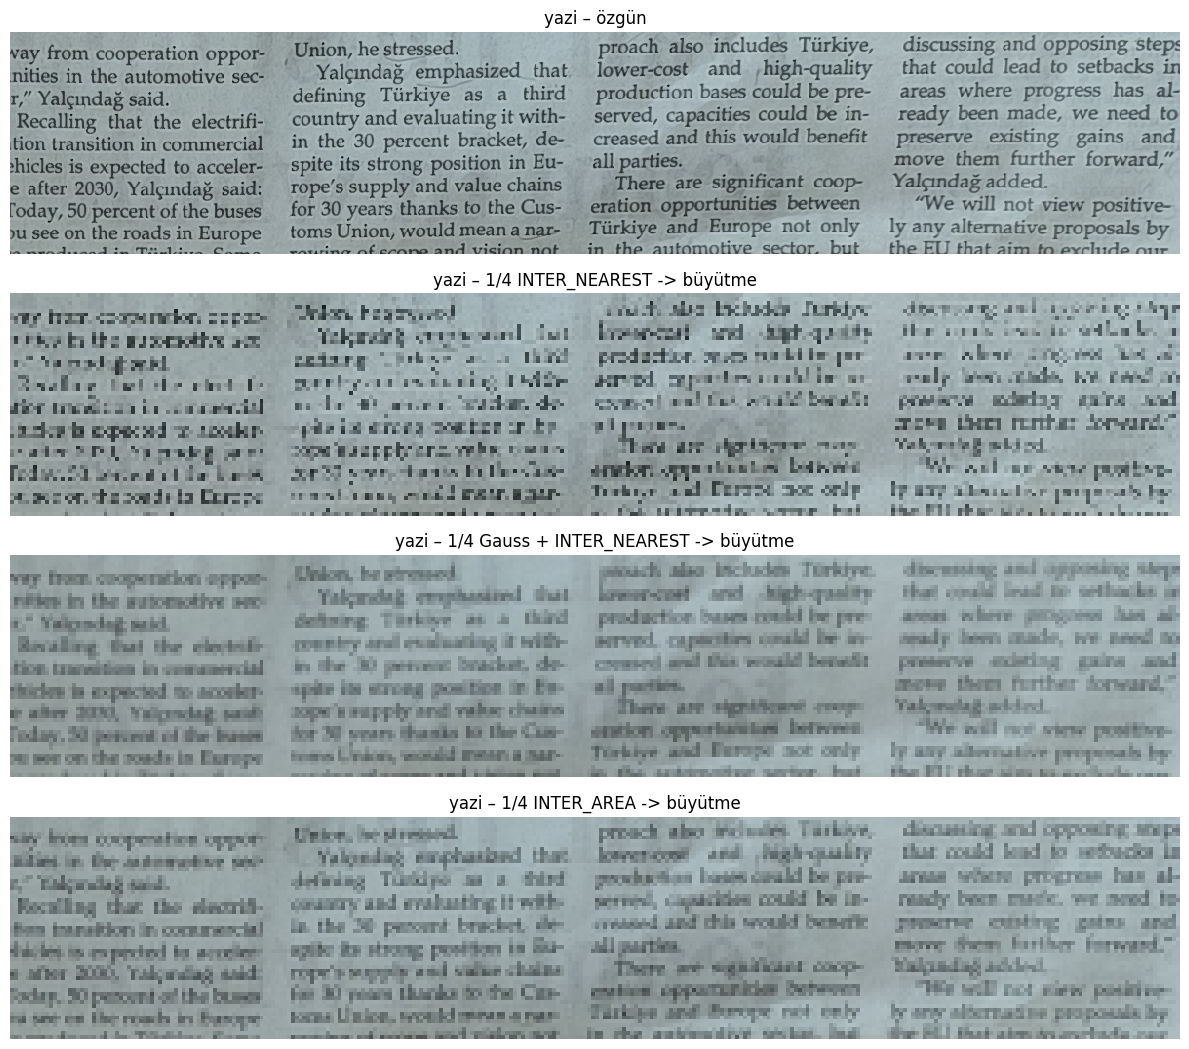

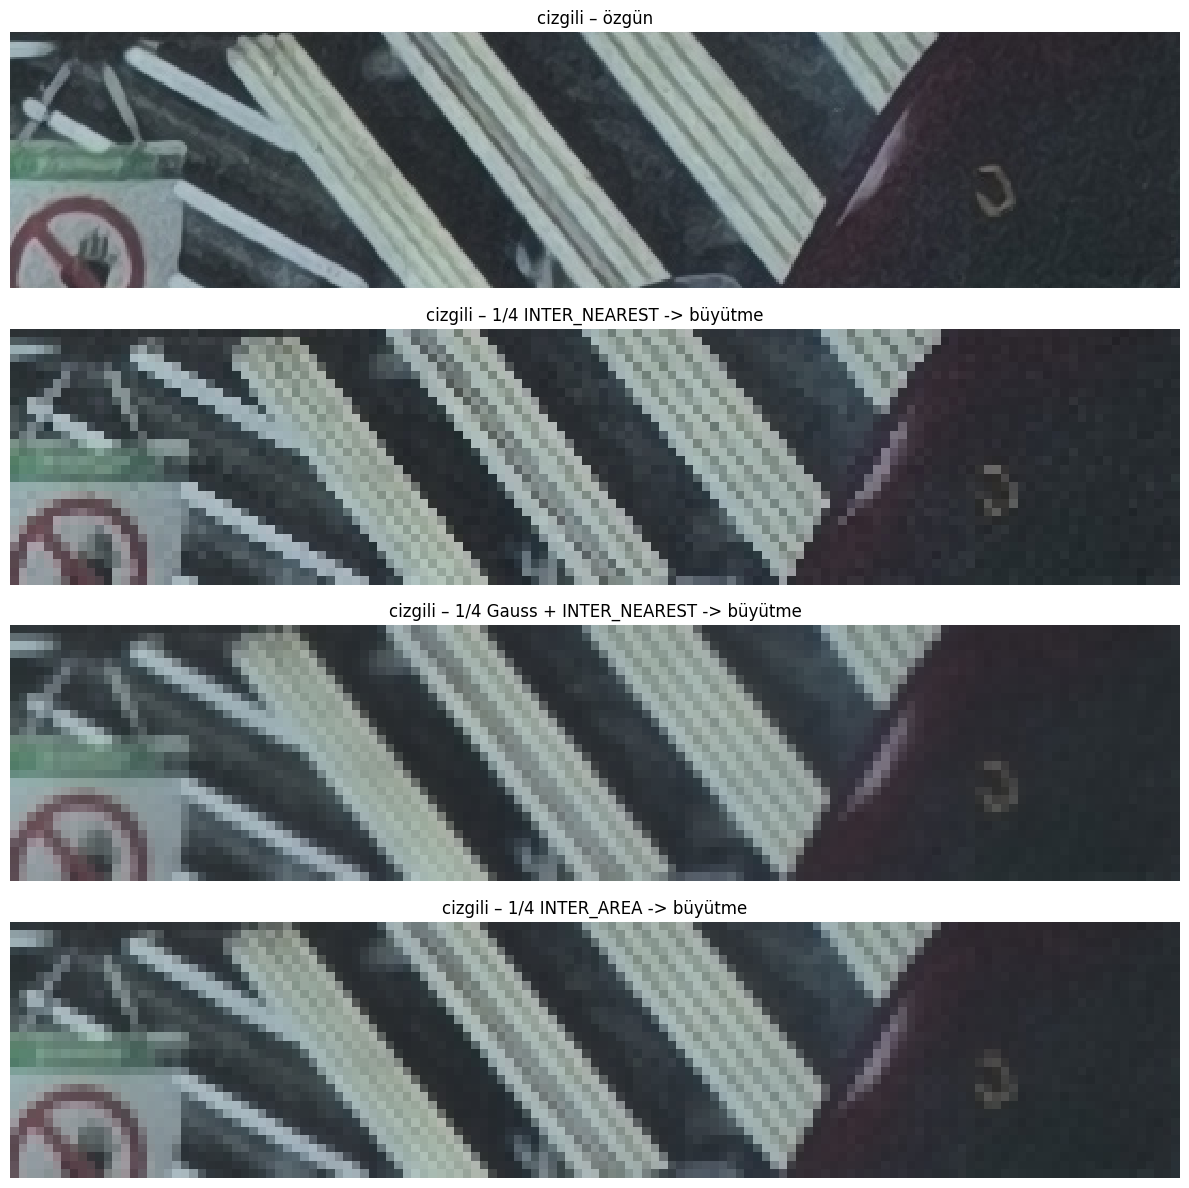

,bolge,yontem,MAE,PSNR_dB
0,yazi,INTER_NEAREST,20.82,16.87
1,yazi,Gauss + INTER_NEAREST,18.61,18.94
2,yazi,INTER_AREA,15.87,20.19
3,cizgili,INTER_NEAREST,8.99,22.71
4,cizgili,Gauss + INTER_NEAREST,9.10,23.84
5,cizgili,INTER_AREA,7.50,25.12


In [38]:
# ---- Geliştirme 4: örtüşme (aliasing) kontrolü — küçültmeden önce Gauss bulanıklaştırma ----
STRIPE_BOX = box(0.74, 0.165, 0.92, 0.195)   # gazete fotoğrafındaki çizgili tavan
AA_SIGMA = 1.5                               # 1/4 küçültme için yaygın seçim: (4 - 1) / 2

def downscale_compare(region, title, fname):
    hh, ww = (region.shape[0] // SCALE) * SCALE, (region.shape[1] // SCALE) * SCALE
    region = region[:hh, :ww]
    small = (ww // SCALE, hh // SCALE)
    variants = {
        "INTER_NEAREST": cv2.resize(region, small, interpolation=cv2.INTER_NEAREST),
        "Gauss + INTER_NEAREST": cv2.resize(cv2.GaussianBlur(region, (0, 0), AA_SIGMA), small,
                                            interpolation=cv2.INTER_NEAREST),
        "INTER_AREA": cv2.resize(region, small, interpolation=cv2.INTER_AREA),
    }
    fig, ax = plt.subplots(len(variants) + 1, 1, figsize=(12, min(22, (len(variants) + 1) * 12 * hh / ww + 1.5)))
    ax[0].imshow(region, interpolation="nearest"); ax[0].set_title(f"{title} – özgün")
    rows = []
    for a, (nm, sm) in zip(ax[1:], variants.items()):
        upv = cv2.resize(sm, (ww, hh), interpolation=cv2.INTER_NEAREST)
        a.imshow(upv, interpolation="nearest"); a.set_title(f"{title} – 1/4 {nm} -> büyütme")
        d = upv.astype(float) - region.astype(float)
        mse = (d ** 2).mean()
        psnr = 10 * np.log10(255 ** 2 / mse) if mse > 0 else np.inf
        rows.append({"bolge": title, "yontem": nm, "MAE": round(np.abs(d).mean(), 2), "PSNR_dB": round(psnr, 2)})
        log("H4_aliasing", title, f"{nm}_PSNR_dB", psnr)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=130); plt.show()
    return rows

sx0, sy0, sx1, sy1 = STRIPE_BOX
rows = downscale_compare(crop, "yazi", "07_aliasing_yazi.png")
rows += downscale_compare(imgs_rgb["normal"][sy0:sy1, sx0:sx1], "cizgili", "07_aliasing_cizgili.png")
df_alias = pd.DataFrame(rows)
df_alias.to_csv(OUT_DIR / "H4_aliasing.csv", index=False, encoding="utf-8-sig")
display(df_alias)

Değerlendirilen bileşen sayısı: 745 / 880
Medyan harf yüksekliği ≈ 11.0 px  ->  1/4 küçültmede ≈ 2.8 px


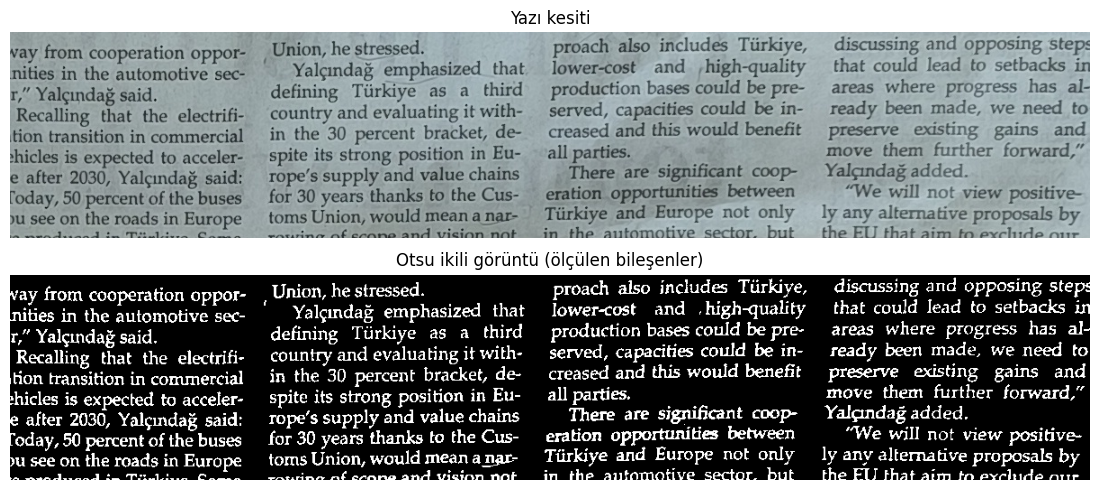

In [39]:
# ---- Geliştirme 5: harf yüksekliğini ölçme (bağlantılı bileşenler) ----
g = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
_, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)   # koyu yazı -> beyaz
n, lab, st, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
hs, ws, ar = st[1:, cv2.CC_STAT_HEIGHT], st[1:, cv2.CC_STAT_WIDTH], st[1:, cv2.CC_STAT_AREA]
keep = (hs >= 4) & (hs <= crop.shape[0] // 3) & (ws <= 3 * hs) & (ar >= 8)     # gürültü ve birleşik blokları ele
letter_h = float(np.median(hs[keep]))
print(f"Değerlendirilen bileşen sayısı: {keep.sum()} / {n - 1}")
print(f"Medyan harf yüksekliği ≈ {letter_h:.1f} px  ->  1/4 küçültmede ≈ {letter_h / SCALE:.1f} px")
log("H4", "normal", "medyan_harf_yuksekligi_px", letter_h)
log("H4", "normal", "kucuk_harf_yuksekligi_px", letter_h / SCALE)

fig, ax = plt.subplots(2, 1, figsize=(12, 5))
ax[0].imshow(crop); ax[0].set_title("Yazı kesiti"); ax[0].axis("off")
ax[1].imshow(bw, cmap="gray"); ax[1].set_title("Otsu ikili görüntü (ölçülen bileşenler)"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "08_harf_yuksekligi.png", dpi=120); plt.show()

## 6. Sonuç tablosu

In [40]:
df_all = pd.DataFrame(RESULTS)
df_all.to_csv(OUT_DIR / "sonuc_tablosu.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_all)} satır -> {OUT_DIR / 'sonuc_tablosu.csv'}")
display(df_all)

112 satır -> outputs\sonuc_tablosu.csv


,bolum,kosul,olcu,deger
0,on_kontrol,golge,hizalama_kayma_px,0.683757
1,on_kontrol,lamba,hizalama_kayma_px,1.168258
2,on_kontrol,normal,kirpilma_herhangi_kanal_%,0.316393
3,on_kontrol,golge,kirpilma_herhangi_kanal_%,0.087498
4,on_kontrol,lamba,kirpilma_herhangi_kanal_%,0.102621
...,...,...,...,...
107,H4_aliasing,cizgili,INTER_NEAREST_PSNR_dB,22.711116
108,H4_aliasing,cizgili,Gauss + INTER_NEAREST_PSNR_dB,23.839646
109,H4_aliasing,cizgili,INTER_AREA_PSNR_dB,25.121472
110,H4,normal,medyan_harf_yuksekligi_px,11.000000


## 7. Rapor notları (her deney için)

| Deney | Tahminim | Ölçümüm | Ne gördüm? | Neden olabilir? | Nasıl kontrol ederim? | Tahmin tuttu mu? |
|---|---|---|---|---|---|---|
| H1 piksel | Gölgede üç kanal azalır; flaşta üçü birlikte artıp 255'e yaklaşır | Gölge/normal oranı defterde R 0,89 – G 0,72 – B 0,51; flaşta kâğıt (164,180,196)→(193,200,219), defter R 250→246 | Gölgede tüm değerler düştü ama kanallar farklı oranda; flaşta kâğıt ve masa aydınlandı, defterin R kanalı ise düştü | Kameranın doğrusal olmayan tonlama eğrisi; otomatik pozlama/beyaz dengesi; defterin R kanalı zaten tavana yakın | Aynı sahneyi Pro modda sabit ISO, enstantane ve beyaz dengesiyle tekrar çekip oranları karşılaştırmak | Gölge: tuttu. Flaş: kısmen tutmadı (defter R düştü, değerler 255'e yaklaşmadı) |
| H2 RGB/HSV | Gölgede RGB maskesi daha çok küçülür; flaşta maskeler aynı kalır veya büyür | RGB: %20,8 → gölge %0,1 → flaş %19,4. HSV: %20,7 → gölge %1,9 → flaş %18,4 | Gölgede iki maske de çöktü; flaşta ikisi de hafifçe küçüldü, defterin sağ üstü maskeden düştü | Gölgede defterin V değeri (221) eşiğin alt sınırının (226) altına indi, H ise sabit kaldı; flaşta parlak kapakta yansıma S'yi düşürüp B'yi artırdı | Beyaz kâğıtla kanal düzeltmesi: gölgede maskeler %19,6'ya döndü (fark ışık şiddetinden); flaşta düzeltme başarısız (%0) | Gölge: RGB kısmı tuttu ama HSV de neredeyse aynı çöktü. Flaş: tutmadı (maskeler küçüldü) |
| H3 b=+40 | Ortalama ≈185,4, kırpma nedeniyle biraz daha az | 183,1 | Artış 40 değil 37,7 oldu | Değerlerin %7,3'ü 255'te kırpıldı | Kırpılan piksel oranını sayıp kaybolan artışı hesaplamak (2,3 seviye) | Tuttu |
| H3 γ | γ=0,5: aydınlanır, ≈192,6; γ=2,0: kararır, ≈82,9 | γ=0,5: 188,4; γ=2,0: 94,3 | Yönler doğru, değerler 4,2 ve 11,4 seviye saptı | Gama doğrusal olmadığı için ortalamanın gaması ≠ gamanın ortalaması (Jensen eşitsizliği) | Tüm pikselleri aynı değerde düz gri bir görüntüde aynı hesabı yapmak; fark sıfır çıkmalı | Yön tuttu, değer tutmadı |
| H4 küçültme | Yazı okunamaz olur; en yakın komşu bulanık/gri, alan ortalaması kopuk/kırık gösterir; büyütme ayrıntıyı geri getirmez | Harf yüksekliği ≈11 px → 1/4'te ≈2,8 px. PSNR: en yakın komşu 16,9 dB, Gauss+en yakın komşu 18,9 dB, alan ortalaması 20,2 dB | En yakın komşuda harfler kopuk ve okunaksız; alan ortalamasında bulanık ama kısmen okunuyor; büyütme ikisinde de ayrıntıyı geri getirmedi | En yakın komşu her 4×4 bloktan tek piksel alıp ince çizgileri atlıyor (örtüşme), bu yüzden kopukluk oluşuyor; alan ortalaması 16 pikseli ortalayıp keskinliği griye çeviriyor | Küçültmeden önce Gauss bulanıklaştırma uygulamak: en yakın komşunun PSNR'si 16,9'dan 18,9 dB'ye çıktı, kopukluklar azaldı | Kısmen tutmadı: büyütmenin ayrıntıyı geri getirmemesi tuttu; iki yöntemin etkisi ters tahmin edildi; alan ortalamasında yazı tamamen okunamaz olmadı |

**"Sarı (turuncu) bir arka plan neden hedef gibi seçildi?"** — Bu deneyde arka plan neredeyse hiç seçilmedi: seçilen piksellerin defter kutusu dışında kalan payı tüm koşullarda %2,4'ün altında. Bunun nedeni eşiklerin dar tutulmasıydı (ör. RGB'de G 90–144, B 15–67). Eşikler gevşetilseydi ya da sıcak renkli bir lamba kullanılsaydı arka plan seçilebilirdi: flaş altında bej masa (162, 148, 137) değerine çıktı; sıcak ışık R'yi artırıp B'yi düşürseydi masa turuncu eşiğe yaklaşırdı. Renk eşiği nesneyi değil piksel değerini seçer; ışık bir arka planı hedefin değer aralığına taşıyabilir.

**"Büyütme kaybolan yazıyı neden geri getirmedi?"** — Gazetedeki harfler yaklaşık 11 piksel yüksekliğindeydi ve 1/4 küçültmede yaklaşık 2,8 piksele indi. Bu boyutta harflerin ince çizgileri ve aralarındaki boşluklar artık temsil edilemiyor; en yakın komşu her 16 pikselden 15'ini attı, alan ortalaması ise onları tek bir gri değerde birleştirdi. Büyütme yalnızca var olan pikselleri tekrarlar veya aralarını doldurur; atılan bilgiyi yeniden üretemez. Bu yüzden küçültmede kaybolan ayrıntı kalıcıdır.

**Sınırlar:**
- Otomatik pozlama ve beyaz dengesi açıktı; fotoğraflar arasındaki fark yalnızca ışığa bağlanamaz.
- "Lamba" koşulu için telefon flaşı kullanıldı; flaş kamerayla aynı eksenden gelir ve parlak kapakta yansıma yaptı.
- JPEG sıkıştırması ve kameranın tonlama eğrisi piksel değerlerini doğrusal olmayan biçimde değiştirir; beyaz kâğıt düzeltmesinin flaşta başarısız olması bunu gösteriyor.
- Gölge, defterin ve kâğıdın farklı bölümlerine farklı düştü (gölgede kâğıt std ≈ 9–15); kâğıda dayalı düzeltme bu yüzden yaklaşık.
- Eşikler tek bir küçük ROI'den belirlendi; sonuçlar seçilen paya (±20) duyarlı. Örneğin V alt sınırı 226 olmasaydı HSV maskesi gölgede çökmeyebilirdi.
- İlk eşikler sıkıştırılmış bir kopyadan hesaplanmıştı; orijinal normal fotoğrafın ROI istatistiğinden bir kez yeniden belirlenip donduruldu.
- Maske alan oranı bir doğruluk ölçütü değildir; yalnızca seçilen piksel miktarını gösterir.
- PSNR piksel farkını ölçer, okunabilirliği ölçmez.

## Yapay zekâ beyanı
| Araç | Kullanım amacı | Etkilediği dosya/hücre | Nasıl doğruladım |
|---|---|---|---|
| Claude (Anthropic) | Defter iskeleti ve tüm analiz kodunun yazılması; Windows uyumluluğu hata ayıklaması | Tüm kod hücreleri | Defteri kendi bilgisayarımda baştan sona çalıştırdım; ödevdeki örnek değerleri (64 → 127,75 / 16,06) ve BGR/RGB dönüşümünü çıktıda kontrol ettim |
| Claude (Anthropic) | Piksel noktaları, ROI, eşik, nesne kutusu ve yazı bölgesi koordinatlarının önerilmesi | H1, H2, H4 parametre hücreleri | Koordinat ızgarası ve ROI görselinde bölgelerin doğru yere düştüğünü, eşiklerin ROI istatistiğinden çıktığını kontrol ettim |
| Claude (Anthropic) | Geliştirme hücreleri (5×5 ortalama, beyaz kâğıt düzeltmesi, örtüşme kontrolü, harf yüksekliği) | Geliştirme 2–5 hücreleri | Çıktı görsellerini ve tablolarını inceledim |
